# IRIS: 02 Lag analysis

How many weeks after heavy rain do national leptospirosis cases rise? This sets the dashboard's alert window.

**Model.** For each lag L from 0 to 8 weeks, a negative binomial regression of weekly national cases on rainfall
L weeks earlier, with two seasonal harmonics and a dummy for each year (which absorbs the 2020 to 2021 COVID
drop and year-to-year reporting changes). The main rainfall measure is the share of provinces above their own
weekly 90th percentile, scaled per 10 percentage points. Mean weekly rainfall (per 50 mm) is a sensitivity
check, and so is a run without 2020 and 2021. This is a simplified version of the distributed-lag approach
in Matsushita et al. (2018): one lag per model rather than a full lag curve.

Input: `data/processed/weekly_national.csv` from notebook 01. Output: `data/processed/lag_results.csv`.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
warnings.filterwarnings('ignore')

ROOT = Path('..') if Path.cwd().name == 'notebooks' else Path('.')
OUT = ROOT / 'data' / 'processed'
MAX_LAG = 8

w = pd.read_csv(OUT / 'weekly_national.csv').sort_values(['iso_year', 'iso_week']).reset_index(drop=True)
for L in range(MAX_LAG + 1):
    w[f'share_l{L}'] = w['share_prov_above_p90'].shift(L) * 10   # per 10 percentage points
    w[f'mm_l{L}'] = w['mean_rain_mm'].shift(L) / 50              # per 50 mm
for k in (1, 2):
    w[f's{k}'] = np.sin(2 * np.pi * k * w['iso_week'] / 52)
    w[f'c{k}'] = np.cos(2 * np.pi * k * w['iso_week'] / 52)
d = w.dropna(subset=['cases'])
print(len(d), 'weeks with cases,', d['iso_year'].min(), 'to', d['iso_year'].max())

227 weeks with cases, 2019 to 2023


In [2]:
def lag_curve(data, var, label):
    rows = []
    for L in range(MAX_LAG + 1):
        m = smf.negativebinomial(f'cases ~ {var}_l{L} + s1 + c1 + s2 + c2 + C(iso_year)', data).fit(disp=0, maxiter=300)
        b, se = m.params[f'{var}_l{L}'], m.bse[f'{var}_l{L}']
        rows.append({'model': label, 'lag_weeks': L, 'rr': np.exp(b),
                     'rr_low': np.exp(b - 1.96 * se), 'rr_high': np.exp(b + 1.96 * se), 'aic': m.aic})
    return pd.DataFrame(rows)

res = pd.concat([
    lag_curve(d, 'share', 'Main: share of provinces above p90 (per 10 pp)'),
    lag_curve(d, 'mm', 'Sensitivity: mean weekly rain (per 50 mm)'),
    lag_curve(d[~d['iso_year'].isin([2020, 2021])], 'share', 'Sensitivity: main without 2020-2021'),
], ignore_index=True)
res['significant'] = res['rr_low'] > 1
res.round(3).to_csv(OUT / 'lag_results.csv', index=False)
res.round(3)

,model,lag_weeks,rr,rr_low,rr_high,aic,significant
0,Main: share of provinces above p90 (per 10 pp),0,0.982,0.896,1.077,2305.347,False
1,Main: share of provinces above p90 (per 10 pp),1,0.994,0.905,1.092,2305.470,False
2,Main: share of provinces above p90 (per 10 pp),2,1.073,0.978,1.176,2303.152,False
3,Main: share of provinces above p90 (per 10 pp),3,1.170,1.074,1.275,2291.592,True
4,Main: share of provinces above p90 (per 10 pp),4,1.134,1.043,1.234,2296.266,True
5,Main: share of provinces above p90 (per 10 pp),5,1.138,1.052,1.231,2294.567,True
6,Main: share of provinces above p90 (per 10 pp),6,1.122,1.036,1.216,2297.166,True
7,Main: share of provinces above p90 (per 10 pp),7,1.068,0.984,1.160,2302.944,False
8,Main: share of provinces above p90 (per 10 pp),8,1.038,0.950,1.134,2304.798,False
9,Sensitivity: mean weekly rain (per 50 mm),0,0.964,0.719,1.292,2305.426,False


In [3]:
main = res[res['model'].str.startswith('Main')]
peak = main.loc[main['rr'].idxmax()]
sig = main.loc[main['significant'], 'lag_weeks']
print(f"Peak lag: {int(peak.lag_weeks)} weeks, RR {peak.rr:.2f} (95% CI {peak.rr_low:.2f} to {peak.rr_high:.2f}) "
      f"per 10-point rise in the share of provinces with extreme weekly rain.")
print(f"Lags with RR significantly above 1: {sig.min()} to {sig.max()} weeks.")
for name, g in res.groupby('model'):
    print(f"  {name}: peak at {int(g.loc[g['rr'].idxmax(), 'lag_weeks'])} weeks")

Peak lag: 3 weeks, RR 1.17 (95% CI 1.07 to 1.28) per 10-point rise in the share of provinces with extreme weekly rain.
Lags with RR significantly above 1: 3 to 6 weeks.
  Main: share of provinces above p90 (per 10 pp): peak at 3 weeks
  Sensitivity: main without 2020-2021: peak at 3 weeks
  Sensitivity: mean weekly rain (per 50 mm): peak at 3 weeks


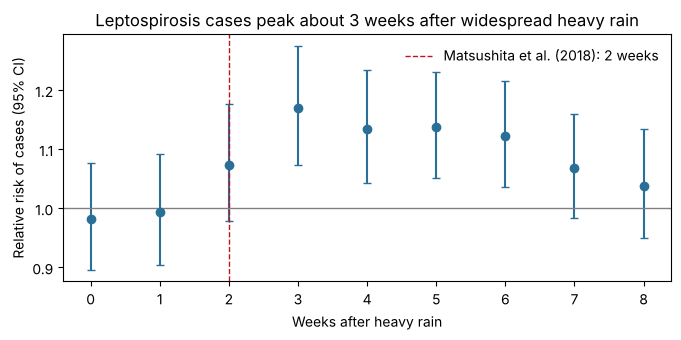

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(main['lag_weeks'], main['rr'], yerr=[main['rr'] - main['rr_low'], main['rr_high'] - main['rr']],
            fmt='o', capsize=3, color='#2a6f97')
ax.axhline(1, color='grey', lw=1)
ax.axvline(2, color='#c1121f', ls='--', lw=1, label='Matsushita et al. (2018): 2 weeks')
ax.set_xlabel('Weeks after heavy rain'); ax.set_ylabel('Relative risk of cases (95% CI)')
ax.set_title('Leptospirosis cases peak about 3 weeks after widespread heavy rain')
ax.legend(frameon=False); fig.tight_layout()
fig.savefig(OUT / 'lag_curve.png', dpi=200)

## Reading the result

The 2-week lag in Matsushita et al. (2018) counts hospital admissions in Manila. The DOH series counts reported
cases by morbidity week, which adds reporting delay, so a peak one week later is consistent with it. Limits:
one national series, 227 usable weeks, missing weeks in 2020 and 2023, and week alignment between CHIRPS dekads
and DOH morbidity weeks is approximate.

## Leptospirosis patterns

Yearly totals and the average week-by-week curve. Cases climb from late July (week 30) and stay high through
December, the typhoon and southwest monsoon season. 2020 and 2021 are low because of COVID-19 disruption.

In [5]:
RAW = ROOT / 'datasets'
dis = pd.read_excel(RAW / 'Diseases Data (for NBL).xlsx').dropna(subset=['Week'])
long = dis.melt(id_vars='Week', var_name='col', value_name='cases')
long['disease'] = long['col'].str.rsplit(' - ', n=1).str[0]
long['iso_year'] = long['col'].str[-4:].astype(int)
long['iso_week'] = long['Week'].astype(int)
long = long[['disease', 'iso_year', 'iso_week', 'cases']]
lep = long[long['disease'] == 'Leptospirosis']
print(lep.groupby('iso_year')['cases'].agg(total='sum', weeks_reported='count'))

           total  weeks_reported
iso_year                        
2019      3278.0              52
2020      1427.0              28
2021      1617.0              52
2022      4773.0              52
2023      5511.0              43


## Storm event study

The heaviest rain weeks of 2019 to 2023 (at least 25% of provinces above their own weekly 90th percentile, events
at least 10 weeks apart). For each, weekly cases from 4 weeks before to 8 weeks after are divided by the average
of the 4 weeks before. The median across events shows the typical response.

In [6]:
ww = w[w['iso_year'].between(2019, 2023)].reset_index(drop=True)
events = []
for i in ww['share_prov_above_p90'].sort_values(ascending=False).index:
    if ww.loc[i, 'share_prov_above_p90'] < 0.25:
        break
    if all(abs(i - j) >= 10 for j in events):
        events.append(i)
rows = []
for i in events:
    base = ww.loc[i - 4:i - 1, 'cases'].mean()
    for k in range(-4, 9):
        if 0 <= i + k < len(ww) and base > 0:
            rows.append({'event_week': ww.loc[i, 'week_start'], 'share_prov_above_p90': ww.loc[i, 'share_prov_above_p90'],
                         'weeks_from_event': k, 'cases': ww.loc[i + k, 'cases'],
                         'ratio_to_before': ww.loc[i + k, 'cases'] / base})
es = pd.DataFrame(rows)
es.round(3).to_csv(OUT / 'event_study.csv', index=False)
print(es['event_week'].nunique(), 'events with case data:', sorted(es['event_week'].unique()))
es.groupby('weeks_from_event')['ratio_to_before'].median().round(2)

11 events with case data: ['2019-08-26', '2020-10-26', '2021-01-11', '2021-07-19', '2021-10-04', '2021-12-13', '2022-04-04', '2022-08-01', '2022-10-24', '2023-01-02', '2023-07-24']


weeks_from_event
-4    1.03
-3    0.54
-2    0.93
-1    1.40
 0    0.59
 1    0.85
 2    1.34
 3    1.98
 4    1.33
 5    1.01
 6    1.02
 7    1.00
 8    0.80
Name: ratio_to_before, dtype: float64

## Negative controls: do other diseases follow rain the same way?

The same model is run for other diseases in the DOH file. Rabies and acute flaccid paralysis have no link to
flooding and serve as negative controls; dengue, typhoid and diarrhoea are water- or rain-related comparisons. If
only leptospirosis shows the 3 to 6 week rise, the result is less likely to be an artefact of seasonality or
reporting.

In [7]:
DISEASES = ['Leptospirosis', 'Dengue', 'Typhoid Fever', 'Acute Bloody Diarrhea', 'Influenza-Like Illness (ILI)',
            'Rabies', 'Acute Flaccid Paralysis (AFP)']
ctl = []
for name in DISEASES:
    dd = w.drop(columns='cases').merge(long[long['disease'] == name], on=['iso_year', 'iso_week'])
    r = lag_curve(dd.dropna(subset=['cases']), 'share', name)
    ctl.append(r.rename(columns={'model': 'disease'}))
ctl = pd.concat(ctl, ignore_index=True)
ctl['significant'] = np.where(ctl['rr_low'] > 1, 'higher', np.where(ctl['rr_high'] < 1, 'lower', ''))
ctl.round(3).to_csv(OUT / 'disease_lag.csv', index=False)
ctl.pivot(index='disease', columns='lag_weeks', values='rr').loc[DISEASES].round(2)

lag_weeks,0,1,2,3,4,5,6,7,8
disease,,,,,,,,,
Leptospirosis,0.98,0.99,1.07,1.17,1.13,1.14,1.12,1.07,1.04
Dengue,0.97,0.92,0.98,0.96,0.94,1.02,1.02,0.99,0.98
Typhoid Fever,0.97,0.90,0.92,0.98,0.98,0.96,1.01,1.03,1.01
Acute Bloody Diarrhea,0.98,0.99,1.01,0.97,0.99,1.01,1.00,0.93,0.94
Influenza-Like Illness (ILI),0.98,0.92,0.94,0.97,0.98,0.98,0.98,1.01,0.97
Rabies,1.02,1.00,1.01,0.99,1.03,1.03,1.02,0.99,0.98
Acute Flaccid Paralysis (AFP),0.95,0.98,1.00,0.97,0.97,1.01,0.99,1.01,0.95


## Forecast model and backtest

One model with rain at lags 2 to 6 weeks together (plus the seasonal harmonics and year dummies) turns the lag
result into a forecast: the rain of the past weeks gives the expected rise in cases over the next weeks, relative
to a week with no extreme rain. To test it honestly, it is fitted on 2019 to 2022 and used to predict 2023, which
it has not seen, against a seasonal-only model. The 2023 year level is unknown at forecast time, so both
predictions are rescaled to the 2023 mean and only the week-to-week pattern is compared.

In [8]:
FC_LAGS = range(2, 7)
for L in FC_LAGS:
    if f'share_l{L}' not in w:
        w[f'share_l{L}'] = w['share_prov_above_p90'].shift(L) * 10
d = w.dropna(subset=['cases'])
RAIN = ' + '.join(f'share_l{L}' for L in FC_LAGS)
BASE = 'cases ~ s1 + c1 + s2 + c2 + C(iso_year)'
train, test = d[d['iso_year'] <= 2022], d[d['iso_year'] == 2023].copy()
X = test.assign(iso_year=2022)
bt = test[['week_start', 'cases']].copy()
scores = []
for name, f in [('Seasonal only', BASE), ('Seasonal + rain (lags 2 to 6)', f'{BASE} + {RAIN}')]:
    m = smf.negativebinomial(f, train).fit(disp=0, maxiter=500)
    p = m.predict(X)
    p = p * test['cases'].mean() / p.mean()
    bt[name] = p.round(1)
    scores.append({'model': name, 'corr': np.corrcoef(p, test['cases'])[0, 1],
                   'mae': np.mean(np.abs(p - test['cases']))})
bt.to_csv(OUT / 'forecast_backtest.csv', index=False)
scores = pd.DataFrame(scores).round(3)
scores.to_csv(OUT / 'forecast_scores.csv', index=False)
scores

,model,corr,mae
0,Seasonal only,0.739,41.027
1,Seasonal + rain (lags 2 to 6),0.803,36.948


In [9]:
final = smf.negativebinomial(f'{BASE} + {RAIN}', d).fit(disp=0, maxiter=500)
coef = pd.DataFrame({'lag_weeks': list(FC_LAGS), 'coef': [final.params[f'share_l{L}'] for L in FC_LAGS]})
coef['unit'] = 'per 10 percentage points of provinces above their weekly 90th percentile'
coef.to_csv(OUT / 'forecast_coefs.csv', index=False)
coef

,lag_weeks,coef,unit
0,2,0.014557,per 10 percentage points of provinces above th...
1,3,0.130128,per 10 percentage points of provinces above th...
2,4,0.020478,per 10 percentage points of provinces above th...
3,5,0.071348,per 10 percentage points of provinces above th...
4,6,0.074828,per 10 percentage points of provinces above th...
